# **EduPredict — Transformer les habitudes d'étude en prédictions fiables du score d'examen**

Ce projet développe un modèle de régression pour prédire le score d'examen des étudiants d'une école supérieure avec une haute précision. L'objectif est de fournir une solution rapide, fiable et accessible à l'équipe pédagogique afin de l'aider à anticiper les résultats, à repérer en amont les étudiants à risque d'échec et à mieux orienter leur accompagnement.

### **Contexte du projet**

Vous êtes un développeur IA junior au sein d'une école supérieure qui souhaite mettre en place un système intelligent capable d'estimer de manière précise le score final que chaque étudiant obtiendra à son examen.

L'objectif est de proposer une solution innovante permettant d'anticiper les résultats, d'identifier en amont les étudiants à risque d'échec et d'aider l'équipe pédagogique à mieux orienter leur accompagnement.

Les données exploitées proviennent du suivi des étudiants (habitudes d'étude, résultats précédents, contexte socio-familial). La description des colonnes est dans le fichier `dictionnaire_des_donnees.md`. La variable cible est le score d'examen (Exam_Score).

### Tâche 1 : Chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns",None)


path = "https://drive.google.com/uc?id=1f82Mj5NW8yx9vVjHNPLrHT-n5Ym3vTJa"

df = pd.read_csv(path,encoding="latin-1")

display(df.shape)

(6607, 20)

### Tâche 2 : Analyse exploratoire (EDA)

Overview on the data, its structure (types, dimensions and a sample from the beginning and end of it) along with a descriptive analysis (mean, meadian, Standard deviation) for integers and (mode,frequence) for categorical data




In [2]:
df.info()
print()
display(df.head())
print()
display(df.tail())
print()
display(df.describe())
print()
display(df.describe(include='object',exclude='int64'))
print()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


C:\Users\Youcode\AppData\Local\Temp\ipykernel_5148\2396392150.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object',exclude='int64'))


,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6529,6607,6607,6607,6517,6540,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,3925,4598,2638,5912,3223,3884,3814


Check for missing values and duplicates

In [3]:
display(df.isna().sum().sort_values(ascending=False))
display(df.duplicated().sum())

Parental_Education_Level      90
Teacher_Quality               78
Distance_from_Home            67
Hours_Studied                  0
Access_to_Resources            0
Parental_Involvement           0
Attendance                     0
Extracurricular_Activities     0
Motivation_Level               0
Internet_Access                0
Previous_Scores                0
Sleep_Hours                    0
Family_Income                  0
Tutoring_Sessions              0
School_Type                    0
Peer_Influence                 0
Learning_Disabilities          0
Physical_Activity              0
Gender                         0
Exam_Score                     0
dtype: int64

np.int64(0)

now for visualization

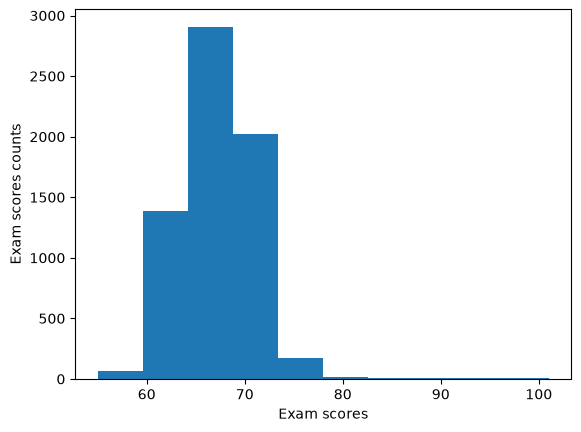

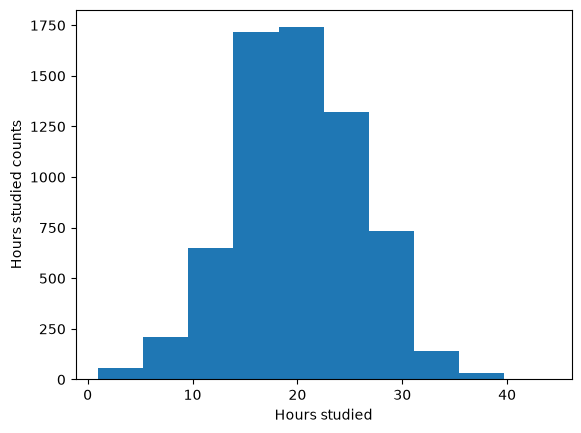

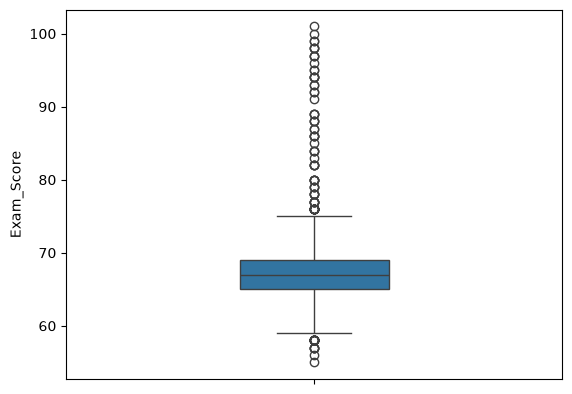

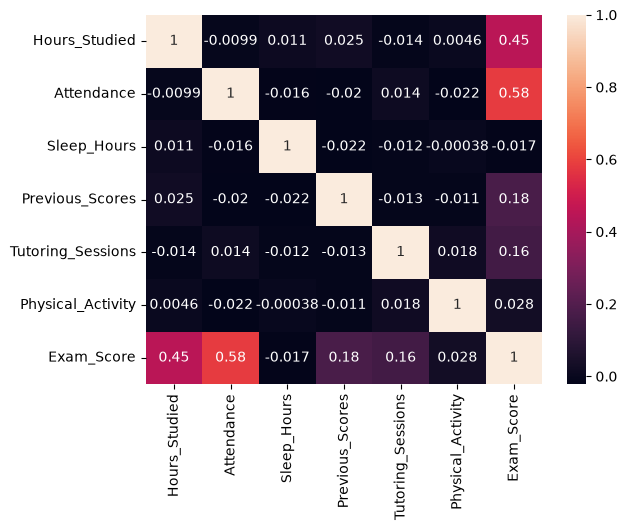

In [4]:
plt.figure()
plt.hist(df.Exam_Score, bins=10)
plt.xlabel("Exam scores")
plt.ylabel("Exam scores counts")
plt.show()

plt.figure()
plt.hist(df.Hours_Studied, bins=10)
plt.xlabel("Hours studied")
plt.ylabel("Hours studied counts")
plt.show()

print()

# mapping = {
#     'Low':0,
#     'Medium':1,
#     'High':2,
#     'Near':0,
#     'Moderate':1,
#     'Far':2,
#     'High School':0,
#     'College':1,
#     'Postgraduate':2
#            }
# copy = df.copy()
# for col in ["Parental_Involvement","Access_to_Resources","Motivation_Level","Family_Income","Teacher_Quality","Parental_Education_Level","Distance_from_Home"]:
#   copy[col] = copy[col].map(mapping)
# copy = pd.get_dummies(copy)
# plt.figure(figsize=(40, 20))
# sns.heatmap(copy.corr(numeric_only=True), annot=True)

sns.boxplot(df['Exam_Score'],width=0.3)
plt.show()

sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

### Tâche 3 : Prétraitement

Now we're gonna fill the missing values with the mode and remove duplicates

In [5]:
df['Parental_Education_Level'] = df['Parental_Education_Level'].fillna(df['Parental_Education_Level'].mode()[0])
df['Teacher_Quality'] = df['Teacher_Quality'].fillna(df['Teacher_Quality'].mode()[0])
df['Distance_from_Home'] = df['Distance_from_Home'].fillna(df['Distance_from_Home'].mode()[0])
df = df.drop_duplicates()

now deleting the outliers

59.0

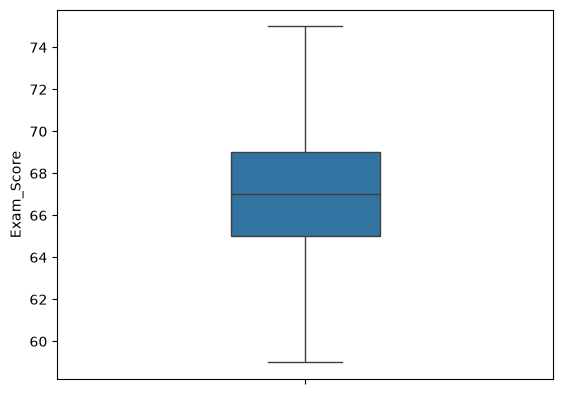

In [6]:
Q1, Q3 = df['Exam_Score'].quantile([.25, .75])
IQR = Q3 - Q1
display(Q1 - 1.5 * IQR)
df = df.query('(@Q1 - 1.5 * @IQR) <= Exam_Score <= (@Q3 + 1.5 * @IQR)')

# df = df[((df['Exam_Score'] - df['Exam_Score'].mean()) / df['Exam_Score'].std()).abs() <= 3]

sns.boxplot(df['Exam_Score'],width=0.3)
plt.show()



one hot encoding and cardinal encoding

In [8]:
# from sklearn.preprocessing import OneHotEncoder

mapping = {
    'Low':0,
    'Medium':1,
    'High':2,
    'Near':0,
    'Moderate':1,
    'Far':2,
    'High School':0,
    'College':1,
    'Postgraduate':2
           }

encoded_df = df.copy()
for col in ["Parental_Involvement","Access_to_Resources","Motivation_Level","Family_Income","Teacher_Quality","Parental_Education_Level","Distance_from_Home"]:
  encoded_df[col] = encoded_df[col].map(mapping)

encoded_df = pd.get_dummies(encoded_df,drop_first=True, dtype=int)
display(encoded_df)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Family_Income,Teacher_Quality,Physical_Activity,Parental_Education_Level,Distance_from_Home,Exam_Score,Extracurricular_Activities_Yes,Internet_Access_Yes,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Gender_Male
0,23,84,0,2,7,73,0,0,0,1,3,0,0,67,0,1,1,0,1,0,1
1,19,64,0,1,8,59,0,2,1,1,4,1,1,61,0,1,1,0,0,0,0
2,24,98,1,1,7,91,1,2,1,1,4,2,0,74,1,1,1,1,0,0,1
3,29,89,0,1,8,98,1,1,1,1,4,0,1,71,1,1,1,0,0,0,1
4,19,92,1,1,6,65,1,3,1,2,4,1,0,70,1,1,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,2,1,7,76,1,1,2,1,2,0,0,68,0,1,1,0,1,0,0
6603,23,76,2,1,8,81,1,3,0,2,2,0,0,69,0,1,1,0,1,0,0
6604,20,90,1,0,6,65,0,3,0,1,2,2,0,68,1,1,1,0,0,0,0
6605,10,86,2,2,6,91,2,2,0,1,3,0,2,68,1,1,0,0,1,0,0


Découpage 80% / 20% avec traintestsplit, puis StandardScaler sur les variables numériques.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# scaler = StandardScaler()
# scaler.set_output(transform='pandas')
# dfs = scaler.fit_transform(df)
# display(dfs)

outcomes = encoded_df["Exam_Score"]
features = encoded_df.drop("Exam_Score",axis=1)
X_train, X_test,y_train, y_test = train_test_split(features,outcomes,train_size=0.8,random_state=1)
display(X_train.shape)
display(X_test.shape)
display(y_train.shape)
display(y_test.shape)
display(encoded_df)
display(df)

(5202, 20)

(1301, 20)

(5202,)

(1301,)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Family_Income,Teacher_Quality,Physical_Activity,Parental_Education_Level,Distance_from_Home,Exam_Score,Extracurricular_Activities_Yes,Internet_Access_Yes,School_Type_Public,Peer_Influence_Neutral,Peer_Influence_Positive,Learning_Disabilities_Yes,Gender_Male
0,23,84,0,2,7,73,0,0,0,1,3,0,0,67,0,1,1,0,1,0,1
1,19,64,0,1,8,59,0,2,1,1,4,1,1,61,0,1,1,0,0,0,0
2,24,98,1,1,7,91,1,2,1,1,4,2,0,74,1,1,1,1,0,0,1
3,29,89,0,1,8,98,1,1,1,1,4,0,1,71,1,1,1,0,0,0,1
4,19,92,1,1,6,65,1,3,1,2,4,1,0,70,1,1,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,2,1,7,76,1,1,2,1,2,0,0,68,0,1,1,0,1,0,0
6603,23,76,2,1,8,81,1,3,0,2,2,0,0,69,0,1,1,0,1,0,0
6604,20,90,1,0,6,65,0,3,0,1,2,2,0,68,1,1,1,0,0,0,0
6605,10,86,2,2,6,91,2,2,0,1,3,0,2,68,1,1,0,0,1,0,0


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

cols_num = ["Hours_Studied", "Attendance", "Sleep_Hours",
            "Previous_Scores", "Tutoring_Sessions", "Physical_Activity"]

scaler = ColumnTransformer(
    [("num", StandardScaler(), cols_num)],
    remainder="passthrough",
)

### Tâche 4 : Entraînement des Modèles de Régression

LinearRegression

In [11]:
from sklearn import pipeline, linear_model
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error

linear_regressor = linear_model.LinearRegression(fit_intercept= False, positive= False)
lr_pipe = pipeline.Pipeline([('scaler', scaler),('linear_regressor', linear_regressor)])
display(lr_pipe.fit(X_train,y_train).score(X_test, y_test))
# linear_regressor.fit(X_train,y_train)
# pred_linear_regressor_train = linear_regressor.predict(X_train)
# display(r2_score(y_train,pred_linear_regressor_train))
# display(root_mean_squared_error(y_train,pred_linear_regressor_train))
# display(mean_absolute_error(y_train,pred_linear_regressor_train))

# pred_linear_regressor_test = linear_regressor.predict(X_test)
# display(r2_score(y_test,pred_linear_regressor_test))
# display(root_mean_squared_error(y_test,pred_linear_regressor_test))
# display(mean_absolute_error(y_test,pred_linear_regressor_test))

# Create the scatter plot with a ideal 1:1 reference line
# sns.regplot(x=pred_linear_regressor_test, y=y_test, line_kws={'color': 'red'})
# plt.xlabel('Predicted Values for Linear Regression')
# plt.ylabel('Actual Values')
# plt.title('Actual vs Predicted')
# plt.show()

-8.568869584834625

In [12]:

random_forest_regressor = RandomForestRegressor(max_depth= 15, min_samples_split= 2, n_estimators= 500)
rf_pipe = pipeline.Pipeline([('scaler', scaler),('random_forest_regressor', random_forest_regressor)])
display(rf_pipe.fit(X_train,y_train).score(X_test, y_test))
# random_forest_regressor.fit(X_train, y_train)

# pred_rf_regressor_train = random_forest_regressor.predict(X_train)
# display(r2_score(y_train,pred_rf_regressor_train))
# display(root_mean_squared_error(y_train,pred_rf_regressor_train))
# display(mean_absolute_error(y_train,pred_rf_regressor_train))

# pred_rf_regressor_test = random_forest_regressor.predict(X_test)
# display(r2_score(y_test,pred_rf_regressor_test))
# display(root_mean_squared_error(y_test,pred_rf_regressor_test))
# display(mean_absolute_error(y_test,pred_rf_regressor_test))

# # Create the scatter plot with a ideal 1:1 reference line
# sns.regplot(x=pred_rf_regressor_test, y=y_test, line_kws={'color': 'red'})
# plt.xlabel('Predicted Values for Random Forest Regressor')
# plt.ylabel('Actual Values')
# plt.title('Actual vs Predicted')
# plt.show()

0.9037063309737845

In [13]:
gradient_boosting_regressor = GradientBoostingRegressor()
gb_pipe = pipeline.Pipeline([('scaler', scaler),('gradient_boosting_regressor', gradient_boosting_regressor)])
display(gb_pipe.fit(X_train,y_train).score(X_test, y_test))


# gradient_boosting_regressor.fit(X_train, y_train)

# pred_gb_regressor_train = gradient_boosting_regressor.predict(X_train)
# display(r2_score(y_train,pred_gb_regressor_train))
# display(root_mean_squared_error(y_train,pred_gb_regressor_train))
# display(mean_absolute_error(y_train,pred_gb_regressor_train))

# pred_gb_regressor_test = gradient_boosting_regressor.predict(X_test)
# display(r2_score(y_test,pred_gb_regressor_test))
# display(root_mean_squared_error(y_test,pred_gb_regressor_test))
# display(mean_absolute_error(y_test,pred_gb_regressor_test))

# # Create the scatter plot with a ideal 1:1 reference line
# sns.regplot(x=pred_gb_regressor_test, y=y_test, line_kws={'color': 'red'})
# plt.xlabel('Predicted Values for Random Forest Regressor')
# plt.ylabel('Actual Values')
# plt.title('Actual vs Predicted')
# plt.show()

0.9463556285345412

In [14]:
sv_pipe = pipeline.Pipeline([('scaler', scaler),('sv_regressor', SVR())])
display(sv_pipe.fit(X_train,y_train).score(X_test, y_test))

sv_regressor = SVR()

# sv_regressor.fit(X_train, y_train)

# pred_sv_regressor_train = sv_regressor.predict(X_train)
# display(r2_score(y_train,pred_sv_regressor_train))
# display(root_mean_squared_error(y_train,pred_sv_regressor_train))
# display(mean_absolute_error(y_train,pred_sv_regressor_train))

# pred_sv_regressor_test = sv_regressor.predict(X_test)
# display(r2_score(y_test,pred_sv_regressor_test))
# display(root_mean_squared_error(y_test,pred_sv_regressor_test))
# display(mean_absolute_error(y_test,pred_sv_regressor_test))

# # Create the scatter plot with a ideal 1:1 reference line
# sns.regplot(x=pred_sv_regressor_test, y=y_test, line_kws={'color': 'red'})
# plt.xlabel('Predicted Values for Random Forest Regressor')
# plt.ylabel('Actual Values')
# plt.title('Actual vs Predicted')
# plt.show()

0.9794022268067836

In [15]:
from sklearn.model_selection import GridSearchCV

lr_params = { "fit_intercept" : [True,False], "positive" : [True,False]}
rfr_params = {"n_estimators": [100, 200, 300, 400, 500],"max_depth": [4,8,12,15], "min_samples_split":[2, 4, 7, 10]}
gbr_params = { "n_estimators":[100, 300, 500], "learning_rate":[0.01, 0.1,0.3], "max_depth":[3, 5], "subsample":[0.5,0.6,0.7,0.8]}
svr_params = { "C":[0.1, 1, 10, 100], "kernel": ["rbf", "linear"], "epsilon":[0.01, 0.1, 0.5]}

scoring = {"r2s": "r2", "nrmses": "neg_root_mean_squared_error","nmaes":"neg_mean_absolute_error"}

In [23]:
lr_grid_search = GridSearchCV(estimator=linear_regressor, param_grid=lr_params, cv=3,scoring=scoring,refit='r2s')

lr_grid_search.fit(X_train, y_train)
print("Best Hyperparameters:", lr_grid_search.best_params_)
print("Best Score:", lr_grid_search.best_score_)

Best Hyperparameters: {'fit_intercept': True, 'positive': False}
Best Score: 0.9897227866649051


In [24]:
rfr_grid_search = GridSearchCV(estimator=random_forest_regressor, param_grid=rfr_params, cv=3,scoring=scoring,refit='r2s')

rfr_grid_search.fit(X_train, y_train)
print("Best Hyperparameters:", rfr_grid_search.best_params_)
print("Best Score:", rfr_grid_search.best_score_)

Best Hyperparameters: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 400}
Best Score: 0.8790495910731876


In [25]:
gbr_grid_search = GridSearchCV(estimator=gradient_boosting_regressor, param_grid=gbr_params, cv=3,scoring=scoring,refit='r2s')

gbr_grid_search.fit(X_train, y_train)
print("Best Hyperparameters:", gbr_grid_search.best_params_)
print("Best Score:", gbr_grid_search.best_score_)

Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.5}
Best Score: 0.9818106179491295


In [ ]:
svr_grid_search = GridSearchCV(estimator=sv_regressor, param_grid=svr_params, cv=3,scoring=scoring,refit='r2s')

svr_grid_search.fit(X_train, y_train)
print("Best Hyperparameters:", svr_grid_search.best_params_)
print("Best Score:", svr_grid_search.best_score_)

In [19]:
best_model = linear_model.LinearRegression(fit_intercept= True, positive= False)
best_pipeline = pipeline.Pipeline([('scaler', scaler),('regressor', best_model)])
best_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Hours_Studied','Attendance','Parental_Involvement',..., 'Peer_Influence_Positive','Learning_Disabilities_Yes','Gender_Male']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically

In [20]:
import joblib

joblib.dump(best_pipeline, "../final_pipeline.joblib")

['../final_pipeline.joblib']